# Project 04: Hospital Readmission Prediction\n## Notebook 03: Evaluation

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, classification_report, brier_score_loss, roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve
import pickle
import shap
import os

# Load data and models
df = pd.read_csv('../data/processed/readmission_cleaned.csv')
with open('../models/scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)
with open('../models/lgbm_calibrated.pkl', 'rb') as f:
    model = pickle.load(f)

# Identify features and target
X = df.drop(['encounter_id', 'patient_nbr', 'readmitted', 'readmitted_30d'], axis=1, errors='ignore')
y = df['readmitted_30d']

# Process features (matching notebook 02 logic for evaluation)
with open('../models/label_encoders.pkl', 'rb') as f:
    le_dict = pickle.load(f)
for col, le in le_dict.items():
    X[col] = le.transform(X[col].astype(str))

X_scaled = scaler.transform(X)

# Predict probabilities
probs = model.predict_proba(X_scaled)[:, 1]
preds = model.predict(X_scaled)

print(f"Evaluation complete on {len(y)} samples.")


/home/ashutosh/miniconda3/envs/ml-env/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/home/ashutosh/miniconda3/envs/ml-env/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/home/ashutosh/miniconda3/envs/ml-env/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/home/ashutosh/miniconda3/envs/ml-env/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/home/ashutosh/miniconda3/envs/ml-env/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


...

/home/ashutosh/miniconda3/envs/ml-env/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/home/ashutosh/miniconda3/envs/ml-env/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/home/ashutosh/miniconda3/envs/ml-env/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/home/ashutosh/miniconda3/envs/ml-env/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Evaluation complete on 71518 samples.


In [2]:

auroc = roc_auc_score(y, probs)
pr_auc = average_precision_score(y, probs)
brier = brier_score_loss(y, probs)

print(f"AUROC: {auroc:.3f}")
print( metrics_df := pd.DataFrame({'Metric': ['AUROC', 'PR-AUC', 'Brier Score'], 'Value': [auroc, pr_auc, brier]}))
metrics_df.to_csv('../models/performance_metrics.csv', index=False)


AUROC: 0.623
        Metric     Value
0        AUROC  0.623071
1       PR-AUC  0.161756
2  Brier Score  0.078865


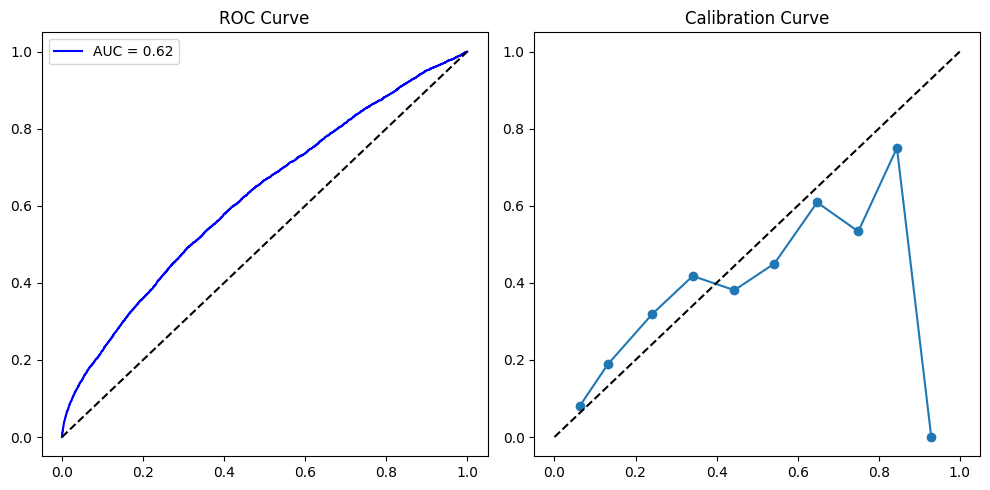

In [3]:

fpr, tpr, _ = roc_curve(y, probs)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, color='blue', label=f'AUC = {auroc:.2f}')
plt.plot([0,1],[0,1],'k--')
plt.title('ROC Curve')
plt.legend()

prob_true, prob_pred = calibration_curve(y, probs, n_bins=10)
plt.subplot(1, 2, 2)
plt.plot(prob_pred, prob_true, marker='o', label='LGBM')
plt.plot([0,1],[0,1],'k--')
plt.title('Calibration Curve')
plt.tight_layout()
plt.savefig('../charts/model_performance_curves.png')
plt.show()


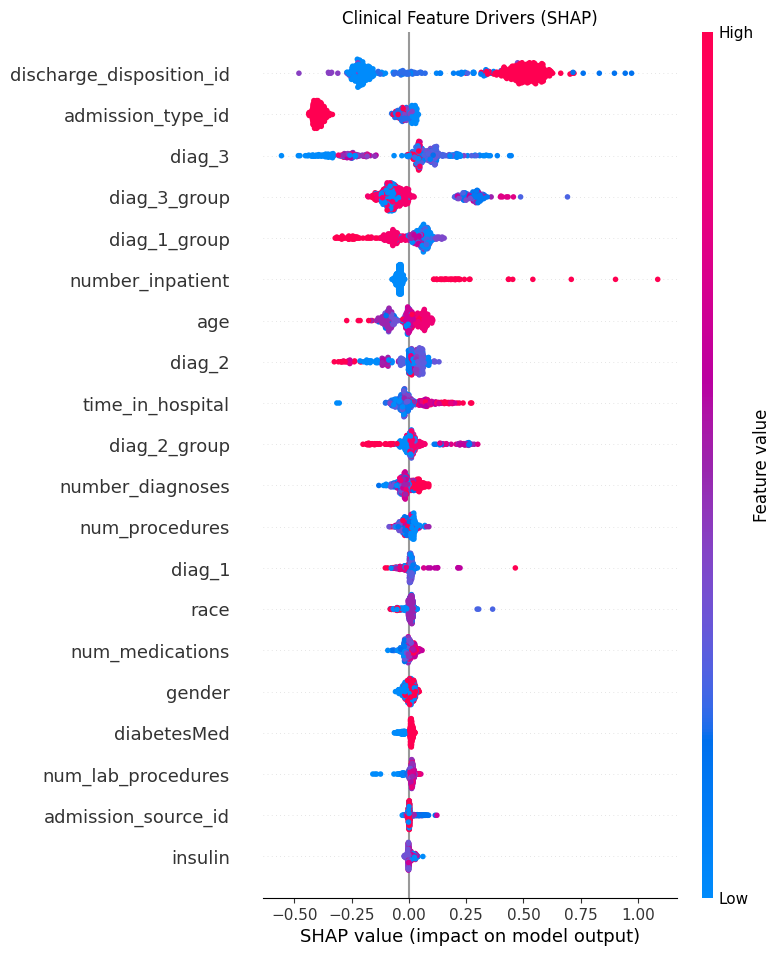

In [4]:

explainer = shap.Explainer(model.estimator, X_scaled)
shap_v = explainer(X_scaled[:500]) # Use fewer samples for speed

plt.figure(figsize=(10,6))
# Using the top-level shap.summary_plot which is most stable
shap.summary_plot(shap_v, X_scaled[:500], feature_names=X.columns, show=False)
plt.title('Clinical Feature Drivers (SHAP)')
plt.savefig('../charts/shap_summary.png', bbox_inches='tight')
plt.show()
